##### Master Degree in Computer Science and Data Science for Economics and Health

# Statistical language models: Markov models

### Prof. Alfio Ferrara

## Introduction

In the previous notebook we predicted the next word by looking at **one word**, the previous one. The model was a table with a row for each previous word, we saw that it is nothing but a table of counts, and we saw its limits: the sentences that it generates are fine word by word and have no plan, and in the toy example it could not know who was buying what. The obvious remedy is to look at more words. How many? And what do we pay for it?

To answer we start from the other end. Before building a model that we can actually use, we ask what the **best possible** language model would be, the one that uses all the information that is available. Then we see why we cannot build it, and what we can do instead. The approach is the one of the **statistical language models**, which are built by counting words in a large corpus. They were the standard until a few years ago, and their limits are the reason why the models of the following notebooks were invented.

We use the same two corpora of the previous notebook, with the same split of the documents (80% training, 10% validation, 10% test), the same vocabulary of the 4,000 most frequent words of the training text, and the symbols `<s>`, `</s>` and `<unk>`.

## The ideal language model

A **language model** is a probability distribution over the sequences of words: a function that gives to every sentence $w_1, \dots, w_n$ (which ends with the symbol `</s>`) a probability $P(w_1, \dots, w_n)$, so that the probabilities of all the possible sentences add up to one. A good model gives a high probability to the sentences that someone could write, and a low one to the others. With it we can **score** a text, **compare** alternatives (which of two sentences is more plausible?) and **generate** (draw a sentence from the distribution).

How can we define such a distribution? The **chain rule** of probability, which is an identity and not an assumption, breaks the probability of a sequence into one factor for each word:

$$P(w_1, \dots, w_n) = P(w_1)\, P(w_2 \mid w_1)\, P(w_3 \mid w_1, w_2) \cdots P(w_n \mid w_1, \dots, w_{n-1}) = \prod_{t=1}^{n} P(w_t \mid w_1, \dots, w_{t-1})$$

Each factor is the probability of a word **given the whole beginning of the sentence**, which we call its **history** $h_t = w_1, \dots, w_{t-1}$. This is the same thing that we did in the previous notebook, the classification of the next word, with one difference: the input is not the previous word but the whole history. A model that knew all these conditional distributions would be **exactly** the language model of the text: nothing is lost, because the decomposition is exact, and nothing is ignored, because every word is predicted with all the information that precedes it. We call it the **ideal** model.

If we want to estimate it from a corpus **by counting**, as the statistical models do, the estimate is the relative frequency of the continuations of a history:

$$\hat{P}(w \mid h) = \frac{c(h, w)}{c(h)}$$

where $c(h)$ is the number of times that the history $h$ occurs at the beginning of a sentence of the training set, and $c(h, w)$ the number of times that it is followed by $w$. To use it we need, for each history, the counts of its possible continuations.

Two questions decide whether this can be done.

1. **Do we have enough examples?** To estimate a distribution from counts we need to have seen the history many times. A history that occurs once says that after it came a certain word, and nothing about the other words that could have come.
2. **Can we keep the counts?** We have to store an index of all the histories and of their continuations.

We measure both on the recipes and on the plots. Here is the first measure, the most radical one: if we consider the whole sentence as the history of its end, how many of the sentences of the validation set have been seen, whole, in the training set?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

from nlp import lm

def prepare(documents):
    train_docs, validation_docs, test_docs = lm.split_documents(documents)
    vocabulary = lm.Vocabulary(train_docs, size=4000)
    sentences = lambda docs: [tuple(vocabulary.encode(s)) for doc in docs for s in doc]    # <s> w1 ... wn </s>, as ids
    return vocabulary, sentences(train_docs), sentences(validation_docs), sentences(test_docs)

corpora = {"recipes": prepare(lm.load_recipes()), "plots": prepare(lm.load_plots())}

rows = {}
for name, (vocabulary, train, validation, test) in corpora.items():
    seen = Counter(train)
    rows[name] = {"training sentences": len(train), "different sentences": len(seen),
                  "occur once": sum(1 for c in seen.values() if c == 1) / len(seen),
                  "validation sentences": len(validation),
                  "validation sentences found whole in the training set": np.mean([s in seen for s in validation])}
pd.DataFrame(rows).T.style.format({"training sentences": "{:,.0f}", "different sentences": "{:,.0f}", "validation sentences": "{:,.0f}",
                                   "occur once": "{:.1%}", "validation sentences found whole in the training set": "{:.1%}"})

,training sentences,different sentences,occur once,validation sentences,validation sentences found whole in the training set
recipes,"84,450","74,166",96.6%,"10,629",14.6%
plots,"45,509","44,361",99.8%,"5,745",2.5%


Of the 84,450 sentences of the training recipes, 74,166 are different, and 96.6% of these occur **once**. Only 14.6% of the sentences of the validation set (1,550 of 10,629) are found whole in the training set: a model that gives to each sentence its relative frequency would give **probability zero to the other 85.4%**. And the ones that are found are the short ones: half of them have at most 3 words (`set aside`, `enjoy`, `preheat oven to degrees`), against a median of 10 words for the sentences that are not found.

In the plots the situation is more extreme: 99.8% of the different sentences occur once, and only 2.5% of the validation sentences (145 of 5,745) are found, with a median of 1 word (`<unk>` alone, for instance). A language is not a list of sentences that repeat: almost every sentence that we will have to evaluate is **new**. A model that can say something about it has to build the probability from its parts.

### Histories of increasing length

A model that has to give a probability to a sentence **it has never seen** can only do it by looking at its parts, and the ideal model does it one word at a time, looking at the history. We call **position** each place of a sentence where a word has to be predicted: every word of every sentence, `</s>` included, is a position, with its history. The sentence `<s> preheat oven to degrees </s>` has five positions, whose histories are `<s>`, `<s> preheat`, `<s> preheat oven`, and so on, up to `<s> preheat oven to degrees` that has to predict `</s>`; the length $k$ of the history is the number of words already written ($k = 0$ for the first word).

Let us measure, for each $k$, what happens to the histories of the training set and to the ones of the validation set. Notice that the row $k$ of the table counts only the positions that have a history of $k$ words, that is, the sentences that are long enough: the longer the history, the fewer and the longer the sentences that we look at, so that the trend of the table mixes two effects, the length of the history and the fact that long sentences are more particular.

- how many positions of the training set have a history of length $k$, and how many **different** histories there are among them (this is the size of the index that we should keep);
- the share of these positions whose history occurs **only once** in the training set (that is, the position is the only example): the estimate $c(h, w) / c(h)$ is then $1$ for the only word that we have seen and $0$ for all the others;
- the share of the positions of the validation set whose history **has been seen** in the training set, and the share whose history **and** next word have been seen (the ones that the model could predict at all);
- the number of **possible** histories, $V^k$, that tells us how large the table could be.

In [2]:
def history_statistics(train, validation, k, V):
    # The history of the word in position k + 1 of a sentence <s> w1 ... wn </s> is <s> w1 ... wk
    histories, pairs = Counter(), set()
    for s in train:
        if len(s) > k + 1:
            histories[s[:k + 1]] += 1
            pairs.add(s[:k + 2])
    examples = [(s[:k + 1], s[:k + 2]) for s in validation if len(s) > k + 1]
    seen_counts = [histories[h] for h, _ in examples if h in histories]
    return {"positions (training)": sum(histories.values()),
            "different histories": len(histories),
            "possible histories": f"10^{k * np.log10(V):.1f}",
            "positions with a history seen once": sum(c for c in histories.values() if c == 1) / max(sum(histories.values()), 1),
            "validation: history seen": np.mean([h in histories for h, _ in examples]),
            "validation: history and next word seen": np.mean([p in pairs for _, p in examples]),
            "median count of the histories seen": np.median(seen_counts) if seen_counts else np.nan}

lengths = [0, 1, 2, 3, 4, 5, 6, 8, 10, 12, 15]
statistics = {name: pd.DataFrame({k: history_statistics(train, validation, k, len(vocabulary)) for k in lengths}).T.rename_axis("k")
              for name, (vocabulary, train, validation, test) in corpora.items()}

def show_history_table(table):
    return table.style.format({"positions (training)": "{:,.0f}", "different histories": "{:,.0f}", "positions with a history seen once": "{:.1%}",
                               "validation: history seen": "{:.1%}", "validation: history and next word seen": "{:.1%}",
                               "median count of the histories seen": "{:.0f}"})

print("Recipes")
show_history_table(statistics["recipes"])

Recipes


,positions (training),different histories,possible histories,positions with a history seen once,validation: history seen,validation: history and next word seen,median count of the histories seen
k,,,,,,,
0,"84,450",1,10^0.0,0.0%,100.0%,99.4%,84450
1,"84,450","1,457",10^3.6,0.5%,99.4%,87.4%,946
2,"82,429","15,772",10^7.2,12.1%,87.3%,62.6%,62
3,"78,840","37,550",10^10.8,37.0%,62.0%,38.6%,10
4,"74,552","51,973",10^14.4,60.8%,37.8%,22.7%,5
5,"68,706","57,380",10^18.0,77.5%,21.0%,12.1%,3
6,"62,655","57,341",10^21.6,87.7%,11.2%,6.7%,2
8,"49,838","48,695",10^28.8,96.1%,3.2%,2.0%,1
10,"37,983","37,618",10^36.0,98.3%,1.0%,0.7%,1


In [3]:
print("Plots")
show_history_table(statistics["plots"])

Plots


,positions (training),different histories,possible histories,positions with a history seen once,validation: history seen,validation: history and next word seen,median count of the histories seen
k,,,,,,,
0,"45,509",1,10^0.0,0.0%,100.0%,98.8%,45509
1,"45,509","1,901",10^3.6,1.2%,98.8%,76.9%,1093
2,"44,397","15,286",10^7.2,24.8%,76.6%,40.0%,20
3,"44,011","31,073",10^10.8,61.3%,39.9%,15.5%,4
4,"43,663","39,534",10^14.4,86.1%,15.5%,4.7%,2
5,"43,168","42,101",10^18.0,96.1%,4.7%,0.9%,1
6,"42,502","42,281",10^21.6,99.1%,0.9%,0.2%,1
8,"40,705","40,693",10^28.8,99.9%,0.0%,0.0%,2
10,"38,037","38,034",10^36.0,100.0%,0.0%,0.0%,1


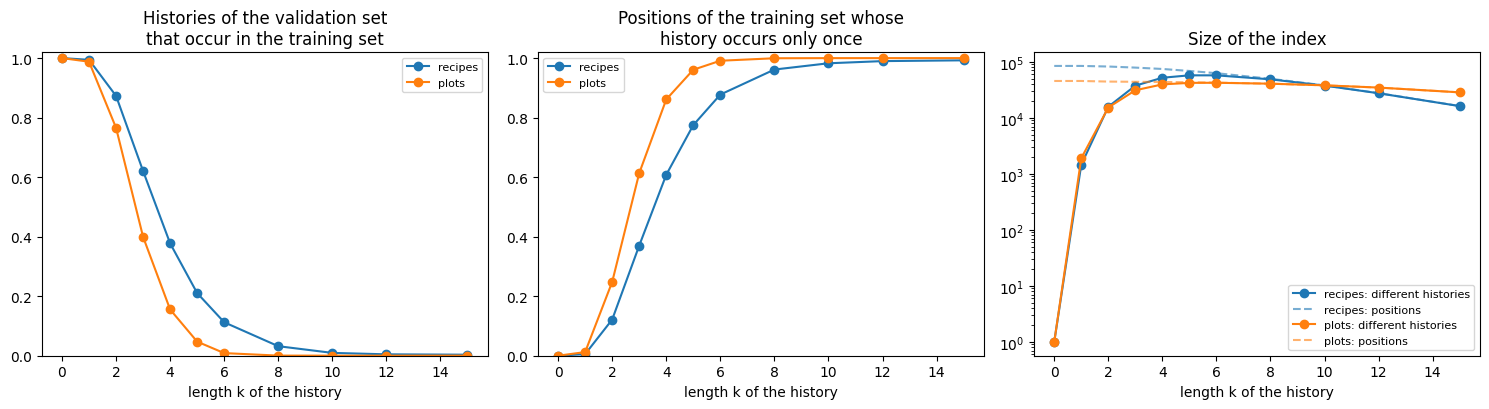

In [4]:
fig, ax = plt.subplots(ncols=3, figsize=(15, 4.2))
for name, color in [("recipes", "tab:blue"), ("plots", "tab:orange")]:
    table = statistics[name]
    ax[0].plot(table.index, table["validation: history seen"], marker="o", color=color, label=name)
    ax[1].plot(table.index, table["positions with a history seen once"], marker="o", color=color, label=name)
    ax[2].plot(table.index, table["different histories"], marker="o", color=color, label=f"{name}: different histories")
    ax[2].plot(table.index, table["positions (training)"], linestyle="--", color=color, alpha=0.6, label=f"{name}: positions")
ax[0].set_title("Histories of the validation set\nthat occur in the training set")
ax[1].set_title("Positions of the training set whose\nhistory occurs only once")
ax[2].set_title("Size of the index")
ax[2].set_yscale("log")
for a in ax:
    a.set_xlabel("length k of the history")
    a.legend(fontsize=8)
ax[0].set_ylim(0, 1.02)
ax[1].set_ylim(0, 1.02)
plt.tight_layout()

This is where the ideal model breaks. The three plots and the tables say the same thing in three ways.

**We do not have enough examples.** In the recipes the history of the validation set has been seen in the training set in 99.4% of the cases for $k = 1$, but in 62.0% for $k = 3$, 21.0% for $k = 5$ and 3.2% for $k = 8$. In the plots the fall is faster: 39.9% for $k = 3$, 4.7% for $k = 5$ and 0.0% for $k = 8$. For a history that has never been seen the estimate $c(h, w) / c(h)$ is not defined: the model has nothing to say. And it is not enough that the history has been seen: the share of the cases in which the history **and** the next word have been seen is lower (12.1% for the recipes and 0.9% for the plots, at $k = 5$), so that even a model that falls back on a guess for the new histories would be right on the next word only in a small part of the cases.

**When we have seen the history, we have seen it a few times.** In the recipes, for $k = 5$ the median count of the histories that we find is 3, and **77.5% of the positions of the training set have a history that occurs only once** (96.1% in the plots). For such a history the count says that the next word is the one that we have seen, with probability 1, and nothing else is possible. This is not an estimate of a probability, it is the memory of one example, the same overfitting that we met in the previous notebook, now in the form of the whole text. For $k = 8$ the share is 96.1% in the recipes.

**We cannot keep the index.** The number of possible histories is $V^k$, and for $k = 5$ it is $10^{18}$. What we actually have to store is smaller, but it grows with the text, and the right plot shows that it does not compress: from $k = 5$ on the number of different histories is almost the same as the number of positions (57,380 against 68,706 for the recipes at $k = 5$, and 57,341 against 62,655 at $k = 6$). The index is **as large as the corpus** and it contains nothing but the corpus, and more text would help only slowly: the number of possible histories of length $k$ grows by a factor $V = 4{,}000$ for each word that we add to the history.

So the ideal model is a *memory of the sentences that we have seen*, and a bad one. It is exact in principle and useless in practice, for two reasons that depend on the same fact: to estimate a conditional distribution by counting we need many examples of its condition, and the conditions that are long are all different.

## The Markov approximation

Since we cannot keep the whole history, we have to give up a part of it. The simplest assumption, the one that gives the name to this notebook, is that **the next word depends only on the last $n - 1$ words**:

$$P(w_t \mid w_1, \dots, w_{t-1}) \approx P(w_t \mid w_{t-n+1}, \dots, w_{t-1})$$

This is a **Markov assumption** of order $n - 1$ (Andrey Markov introduced these chains in 1913, studying the sequence of vowels and consonants in Pushkin's *Eugene Onegin*): given the last $n - 1$ words, the rest of the history does not matter. A model built on it is an **$n$-gram model**, and the sentence is scored with

$$P(w_1, \dots, w_n) \approx \prod_{t=1}^{n} P(w_t \mid w_{t-n+1}, \dots, w_{t-1}),$$

where the first words of the sentence are preceded by the symbol `<s>`. The estimate by counting is the same as before, with the **context** of $n - 1$ words in place of the history: $\hat{P}(w \mid c) = c(c, w) / c(c)$.

- $n = 1$, **unigram**: the context is empty and the model is the relative frequency of the words, the point of reference of the previous notebook.
- $n = 2$, **bigram**: the context is the previous word. It is the table of the previous notebook.
- $n = 3$, **trigram**: the context is made of the two previous words. And so on: **4-gram**, 5-gram.

The order $n$ is the **memory** of the model, and the assumption is a trade-off, not a free lunch. With a small $n$ the contexts are short, and they occur many times in the text: the estimates are reliable, but the model ignores almost all the history, and we expect the text that it generates to lose coherence. With a large $n$ the model sees more of what it has written, but the contexts become as rare as the histories that we have just measured, and the estimates are not reliable. We measure it on the same two corpora: for each context length $m = n - 1$, how many different contexts there are, how many times they occur, and how many of the contexts of the validation set we have seen.

In [5]:
def context_statistics(train, validation, m, V):
    # The context of a word is made of the m words that precede it (with <s> on the left when the sentence has fewer)
    def examples(sentences):
        for s in sentences:
            padded = (s[0],) * (m - 1) + s if m > 0 else s
            for t in range(max(m, 1), len(padded)):
                yield (padded[t - m:t] if m > 0 else ()), (padded[t - m:t + 1] if m > 0 else padded[t:t + 1])
    context_counts, pair_counts = Counter(), Counter()
    for c, p in examples(train):
        context_counts[c] += 1
        pair_counts[p] += 1
    validation_examples = list(examples(validation))
    return {"n": m + 1,
            "possible contexts": f"10^{m * np.log10(V):.1f}",
            "different contexts": len(context_counts),
            "contexts seen once (% of the different ones)": np.mean([c == 1 for c in context_counts.values()]),
            "validation: context seen": np.mean([c in context_counts for c, _ in validation_examples]),
            "validation: context seen at least 5 times": np.mean([context_counts[c] >= 5 for c, _ in validation_examples]),
            "validation: context and next word seen": np.mean([p in pair_counts for _, p in validation_examples])}

memory = {name: pd.DataFrame({m: context_statistics(train, validation, m, len(vocabulary)) for m in range(0, 7)}).T.rename_axis("m = n - 1").astype({"n": int})
          for name, (vocabulary, train, validation, test) in corpora.items()}

def show_memory_table(table):
    return table.style.format({"different contexts": "{:,.0f}", "contexts seen once (% of the different ones)": "{:.1%}", "validation: context seen": "{:.1%}",
                               "validation: context seen at least 5 times": "{:.1%}", "validation: context and next word seen": "{:.1%}"})

print("Recipes")
show_memory_table(memory["recipes"])

Recipes


,n,possible contexts,different contexts,contexts seen once (% of the different ones),validation: context seen,validation: context seen at least 5 times,validation: context and next word seen
m = n - 1,,,,,,,
0,1,10^0.0,1,0.0%,100.0%,100.0%,100.0%
1,2,10^3.6,"3,999",0.0%,100.0%,99.9%,92.2%
2,3,10^7.2,"116,261",58.7%,92.2%,82.8%,71.1%
3,4,10^10.8,"323,030",76.3%,72.5%,55.6%,51.2%
4,5,10^14.4,"475,135",85.8%,54.7%,39.8%,39.6%
5,6,10^18.0,"549,234",90.6%,45.1%,33.9%,34.0%
6,7,10^21.6,"580,364",92.9%,40.7%,31.9%,31.6%


In [6]:
print("Plots")
show_memory_table(memory["plots"])

Plots


,n,possible contexts,different contexts,contexts seen once (% of the different ones),validation: context seen,validation: context seen at least 5 times,validation: context and next word seen
m = n - 1,,,,,,,
0,1,10^0.0,1,0.0%,100.0%,100.0%,100.0%
1,2,10^3.6,"3,999",0.0%,100.0%,100.0%,88.4%
2,3,10^7.2,"164,834",63.6%,88.5%,76.4%,57.6%
3,4,10^10.8,"449,825",81.9%,59.2%,39.3%,30.2%
4,5,10^14.4,"645,036",92.2%,33.6%,20.8%,17.5%
5,6,10^18.0,"719,865",96.5%,22.0%,15.7%,13.6%
6,7,10^21.6,"739,469",97.9%,18.6%,14.7%,12.7%


The table says what we gain by shortening the context. In the recipes, with $n = 2$ (one word of context) the contexts are 3,999, they are almost all frequent (99.9% of the contexts of the validation set occur at least 5 times in the training set) and the pairs (context, next word) of the validation set that have been seen are **92.2%**, the same 7.8% of unseen pairs of the previous notebook. With $n = 3$ the contexts are 116,261, and 58.7% of them occur once; the share of the pairs seen falls to **71.1%**; with $n = 4$ it is 51.2%, and with $n = 5$ 39.6%. The plots are one step behind: 88.4% with $n = 2$, 57.6% with $n = 3$, 30.2% with $n = 4$, 17.5% with $n = 5$.

Two things in the table are worth noticing. The first is that the Markov assumption **works as intended**: with two or three words of context almost all the contexts that we meet in the validation set have been seen several times (82.8% of the recipes with $n = 3$, at least 5 times), and for $n = 2$ and $n = 3$ the problem of the full history is at least softened. The second is that **it does not solve the problem**, it only moves it: for any order the pairs (context, next word) that we have never seen are a share that grows with $n$ (28.9% of the recipes already with $n = 3$), and every one of them would receive probability zero. A model that does so is not a language model, because a new sentence is the normal case, as we have seen above.

So we have a knob, the order $n$, with two opposite effects. If $n$ is small we have the counts and we lack the memory: the text that the model generates has no coherence beyond a couple of words, as in the previous notebook. If $n$ is large we have the memory and we lack the counts. We will see both effects, in the perplexity and in the text that the models generate. But the table already tells us that **whatever order we choose, we have to estimate the probability of the events that we have never seen**. This is the problem that we solve next: how to approximate a probability estimate that the counts alone cannot give.

## A toy example: how much memory do we need?

We start again from the toy example of the previous notebook, with the same rule and the same 400 sentences: three people, four drinks, four foods and five verbs, in sentences of three words, where `anna` only buys drinks, `luca` only buys foods and `marco` buys both. The model that looks at the previous word could not know who was buying, and it generated impossible sentences such as `anna buys pasta`. This time we count in the way that the statistical language models do, with a context of $n - 1$ words, and we write the code from scratch: it is no more than counting.

In [7]:
people = ["anna", "marco", "luca"]
drinks = ["coffee", "tea", "milk", "juice"]
foods = ["bread", "pasta", "rice", "cake"]
likes_of = {"anna": drinks, "marco": drinks + foods, "luca": foods}      # what a person buys or likes

rng = np.random.default_rng(0)
toy_sentences = []
for _ in range(400):
    person, kind = rng.choice(people), rng.random()
    if kind < 0.3:
        toy_sentences.append([person, "drinks", rng.choice(drinks)])
    elif kind < 0.6:
        toy_sentences.append([person, "eats", rng.choice(foods)])
    elif kind < 0.8:
        toy_sentences.append([person, "cooks", rng.choice(foods)])
    else:
        toy_sentences.append([person, rng.choice(["buys", "likes"]), rng.choice(likes_of[person])])

def positions_of(sentence, n):
    # The words to be predicted, with the n - 1 words that precede them (<s> on the left at the beginning of the sentence)
    padded = ["<s>"] * (n - 1) + sentence + ["</s>"]
    for t in range(n - 1, len(padded)):
        yield tuple(padded[t - n + 1:t]), padded[t]

def count_ngrams(sentences, n):
    contexts, pairs = Counter(), Counter()
    for sentence in sentences:
        for context, word in positions_of(sentence, n):
            contexts[context] += 1
            pairs[context + (word,)] += 1
    return contexts, pairs

counts = {n: count_ngrams(toy_sentences, n) for n in (1, 2, 3)}
print({n: (len(c), len(p)) for n, (c, p) in counts.items()}, "(different contexts, different pairs)")

def next_is(context, n, group):
    contexts, pairs = counts[n]
    return sum(c for key, c in pairs.items() if key[:-1] == context and key[-1] in group) / contexts[context]

pd.DataFrame({"next word is a drink": {" ".join(c): next_is(c, n, drinks) for n, c in [(2, ("buys",)), (3, ("anna", "buys")), (3, ("marco", "buys")), (3, ("luca", "buys"))]},
              "next word is a food": {" ".join(c): next_is(c, n, foods) for n, c in [(2, ("buys",)), (3, ("anna", "buys")), (3, ("marco", "buys")), (3, ("luca", "buys"))]}}
             ).rename_axis("context").style.format("{:.2f}")

{1: (1, 17), 2: (17, 54), 3: (47, 112)} (different contexts, different pairs)


,next word is a drink,next word is a food
context,,
buys,0.51,0.49
anna buys,1.00,0.00
marco buys,0.56,0.44
luca buys,0.00,1.00


Counting is all there is, and the numbers are small: with one word of context ($n = 2$) the toy has 17 contexts and 54 different pairs (context, next word), with two words ($n = 3$) 47 contexts and 112 pairs. The table shows what the extra word buys. After `buys` alone the next word is a drink in 51% of the cases and a food in 49%: the model of the previous notebook could not do better. With two words the preferences of each person come out of the counts: after `anna buys` the next word is always a drink (1.00), after `luca buys` always a food, after `marco buys` it is a drink in 56% of the cases and a food in 44%.

In [8]:
def toy_generate(n, rng, max_words=8):
    contexts, pairs = counts[n]
    text = ["<s>"] * (n - 1)
    for _ in range(max_words):
        context = tuple(text[len(text) - (n - 1):]) if n > 1 else ()
        options = [(key[-1], c) for key, c in pairs.items() if key[:-1] == context]
        words, weights = zip(*options)
        word = rng.choice(words, p=np.array(weights) / sum(weights))
        if word == "</s>":
            break
        text.append(word)
    return text[n - 1:]

def possible(sentence):
    # True if the rule that generated the data could have produced the sentence
    if len(sentence) != 3 or sentence[0] not in people:
        return False
    person, verb, thing = sentence
    return (thing in drinks if verb == "drinks" else thing in foods if verb in ("eats", "cooks")
            else thing in likes_of[person] if verb in ("buys", "likes") else False)

toy_words = ["<unk>", "<s>", "</s>"] + sorted({w for s in toy_sentences for w in s})
toy_ids = [tuple(toy_words.index(w) for w in ["<s>"] + s + ["</s>"]) for s in toy_sentences]

from nlp.ngram import NGramModel

rows = {}
for n in (1, 2, 3):
    sampler = np.random.default_rng(n)
    generated = [toy_generate(n, sampler) for _ in range(2000)]
    contexts, pairs = counts[n]
    loss = -np.mean([np.log(pairs[context + (word,)] / contexts[context]) for s in toy_sentences for context, word in positions_of(s, n)])
    rows[f"n = {n}"] = {"perplexity on the training set (from scratch)": np.exp(loss),
                        "same, with the module nlp.ngram": NGramModel(n, len(toy_words)).fit(toy_ids).perplexity(toy_ids, method="mle"),
                        "generated sentences that are impossible": np.mean([not possible(s) for s in generated])}
    if n == 3:
        print("n = 3:", "; ".join(" ".join(toy_generate(3, sampler)) for _ in range(6)))
pd.DataFrame(rows).T.style.format({"perplexity on the training set (from scratch)": "{:.3f}", "same, with the module nlp.ngram": "{:.3f}",
                                    "generated sentences that are impossible": "{:.1%}"})

n = 3: anna eats cake; luca eats rice; marco eats pasta; luca eats rice; luca likes cake; anna eats cake


,perplexity on the training set (from scratch),"same, with the module nlp.ngram",generated sentences that are impossible
n = 1,12.772,12.772,99.9%
n = 2,2.796,2.796,6.4%
n = 3,2.707,2.707,0.0%


The perplexity on the training set computed from scratch and the one of the module `nlp.ngram` are the same (12.772, 2.796 and 2.707), and the last two are the exponentials of the lowest losses of the previous notebook (1.028 with one word of context, 0.996 with two): the counts give back exactly those numbers.

The generated sentences make the point. With $n = 1$ (no memory) 99.9% of the sentences are impossible: the model draws words with their frequency, with no order and no length. With $n = 2$ 6.4% are impossible, in line with the 6.8% that the exact frequencies give in the previous notebook (2,000 sentences, about half a point of noise): the model cannot know who is buying. With $n = 3$ **none** of the 2,000 sentences is impossible, and the six that we print are all fine. In this world two words of memory are enough, because the rule looks back at the person and no further, and we have paid for it with more contexts (47 instead of 17). The real text does not have such a short rule.

## Recipes: counting with more memory

We now count on the recipes, with the module `nlp.ngram` that does the same things on the real corpus (the contexts are stored as sorted arrays of numbers, so that it works in a few seconds on a million words; it handles orders up to $n = 5$). We fit the models of order $n = 1, \dots, 5$ on the training set and we evaluate them on the validation set with the **perplexity**, as in the previous notebooks. First of all with the pure counts, the **maximum likelihood** estimate $\hat{P}(w \mid c) = c(c, w) / c(c)$ that we have used so far: what happens when we give more memory to the model?

In [9]:
models = {name: {n: NGramModel(n, len(vocabulary)).fit(train) for n in range(1, 6)}
          for name, (vocabulary, train, validation, test) in corpora.items()}

def maximum_likelihood_table(name):
    vocabulary, train, validation, test = corpora[name]
    rows = {}
    for n, model in models[name].items():
        X, y = model.positions(validation)
        p = model.probabilities(X, y, method="mle")
        with np.errstate(divide="ignore"):
            rows[n] = {"training perplexity": model.perplexity(train, method="mle"),
                       "validation positions with probability 0": (p == 0).mean(),
                       "validation perplexity": float(np.exp(-np.log(p).mean()))}
    return pd.DataFrame(rows).T.rename_axis("n")

format_mle = {"training perplexity": "{:.1f}", "validation positions with probability 0": "{:.1%}", "validation perplexity": "{:.1f}"}
maximum_likelihood_table("recipes").style.format(format_mle)

,training perplexity,validation positions with probability 0,validation perplexity
n,,,
1,306.4,0.0%,304.6
2,39.9,7.8%,inf
3,10.7,28.9%,inf
4,4.7,48.8%,inf
5,3.3,60.4%,inf


With the pure counts the model learns the training text better and better as the memory grows: the perplexity on the training set falls from 306.4 ($n = 1$) to 39.9, 10.7, 4.7 and 3.3 ($n = 5$), as if at every position the model had to choose among three words. On the validation set it is the opposite. The share of the positions to which the model gives probability **zero** grows from 7.8% ($n = 2$, the unseen pairs of the previous notebook) to 28.9%, 48.8% and 60.4%, and the perplexity is **infinite** for every $n \ge 2$: one zero is enough, because the logarithm of zero is minus infinity. Only the unigram has a finite perplexity (304.6), because all the words of the vocabulary have been seen.

This is the overfitting of the previous notebook again: **counting is fitting without any restraint**. The model knows its training text by heart and has nothing to say about a text that is only a little different. The question is not any more how much memory we can give to the model, but what we do with what it has not seen.

### Estimating what we have not seen

The counts give probability zero to everything that was not in the training set, and the more memory the model has, the more it does not see. We need an estimate of the probability that **does not depend only on the counts of the event**. There are many; we use two, the simplest ones.

1. **Add-$k$ smoothing.** We pretend that we have seen each word $k$ more times after each context: $\hat{P}(w \mid c) = \dfrac{c(c, w) + k}{c(c) + kV}$. Every word, even a new one, receives a small probability, and a context that was never seen gives the uniform distribution. We used it in the previous notebook (for $n = 2$ and $k = 0.01$), and $k$ is chosen on the validation set.
2. **Interpolation** of the orders. A context of two words that has never been seen is not useless: its last word has been seen. We estimate the probability as a **weighted sum** of the maximum likelihood estimates of all the orders, from the one with the longest context to the one with no context at all:
$$P(w \mid w_{t-n+1}, \dots, w_{t-1}) = \sum_{j=0}^{n-1} \lambda_j \, \hat{P}(w \mid w_{t-j}, \dots, w_{t-1}), \qquad \lambda_j \ge 0, \ \sum_j \lambda_j = 1.$$
The model leans on the long context when it has it, and on the short ones when it has not. The weights $\lambda_j$ are the only parameters that we need to estimate, and we choose them on the validation set, with the values that maximize the probability of the validation text (an iterative procedure called *expectation-maximization*). They are $n$ numbers fitted on more than a hundred thousand positions, so we do not expect them to adapt to the validation set; we check it, fitting them on one half of the validation sentences and measuring on the other half.

In [10]:
grid = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

def crossfit_perplexity(model, sentences):
    # The weights are fitted on one half of the sentences and used on the other half, and the other way round
    half = len(sentences) // 2
    a, b = sentences[:half], sentences[half:]
    size = lambda s: len(model.positions(s)[1])
    loss = (model.log_loss(b, method="interpolation", weights=model.fit_weights(a)) * size(b)
            + model.log_loss(a, method="interpolation", weights=model.fit_weights(b)) * size(a)) / (size(a) + size(b))
    return float(np.exp(loss))

def smoothing_table(name):
    vocabulary, train, validation, test = corpora[name]
    rows = {}
    for n, model in models[name].items():
        add_k = {k: model.perplexity(validation, method="add_k", k=k) for k in grid}
        best = min(add_k, key=add_k.get)
        weights = model.fit_weights(validation)
        rows[n] = {"add-k: best k": best, "add-k: perplexity": add_k[best],
                   "interpolation: perplexity": model.perplexity(validation, method="interpolation", weights=weights),
                   "interpolation, weights fitted on the other half": crossfit_perplexity(model, validation),
                   "weights of the orders 1, ..., n": " / ".join(f"{w:.2f}" for w in weights)}
    return pd.DataFrame(rows).T.rename_axis("n")

format_smoothing = {"add-k: best k": "{:g}", "add-k: perplexity": "{:.1f}", "interpolation: perplexity": "{:.1f}", "interpolation, weights fitted on the other half": "{:.1f}"}
smoothing = {"recipes": smoothing_table("recipes")}
smoothing["recipes"].style.format(format_smoothing)

,add-k: best k,add-k: perplexity,interpolation: perplexity,"interpolation, weights fitted on the other half","weights of the orders 1, ..., n"
n,,,,,
1,0.0001,304.6,304.6,304.6,1.00
2,0.01,68.0,64.4,64.4,0.13 / 0.87
3,0.01,109.4,50.2,50.2,0.13 / 0.43 / 0.44
4,0.001,263.3,49.6,49.6,0.13 / 0.43 / 0.37 / 0.08
5,0.001,504.5,49.6,49.6,0.13 / 0.43 / 0.37 / 0.08 / 0.00


**Add-$k$** works for $n = 2$ (68.0 with $k = 0.01$, the number of the previous notebook), but it gets worse as the memory grows, even if $k$ is chosen on the validation set for each order: 109.4 for $n = 3$, 263.3 for $n = 4$, 504.5 for $n = 5$. The reason is that it treats all the events that we have not seen in the same way. A context of three words that has been seen five times gets, with $k = 0.001$, about 4 added counts spread on 4,000 words, and a context that has never been seen gets the uniform distribution, which is the worst thing that we could say: the last word of the context is known and it says a lot.

**Interpolation** does what add-$k$ cannot. It is never worse than the order below (the weights could give it zero) and it gets 64.4 ($n = 2$), 50.2 ($n = 3$) and 49.6 ($n = 4$ and $n = 5$): the gain is large up to three words of memory (22% with the third word) and then it stops. The weights say why. For $n = 3$ they are 0.13 (no context), 0.43 (one word) and 0.44 (two words); for $n = 4$, 0.13 / 0.43 / 0.37 / 0.08; for $n = 5$ the weight of the fifth order is 0.00. Even when it has a long context, the model gives more than half of its weight to the contexts of at most one word, and the fifth order is not used at all, which is consistent with the fact that 60.4% of the pairs of the validation set have not been seen with that memory. Fitting the weights on one half of the validation sentences and measuring on the other half gives the same perplexities (the two columns coincide), so the weights do not adapt to the validation set.

A comparison with the previous notebook. A bigram interpolated with the unigram (64.4) is better than the table with the early stopping (68.4) and than the table with the best weight decay (65.5), and it needs no training. The differences of a few points are not tested, but the order is clear: counting and smoothing is a competitor of the network that learned the same table.

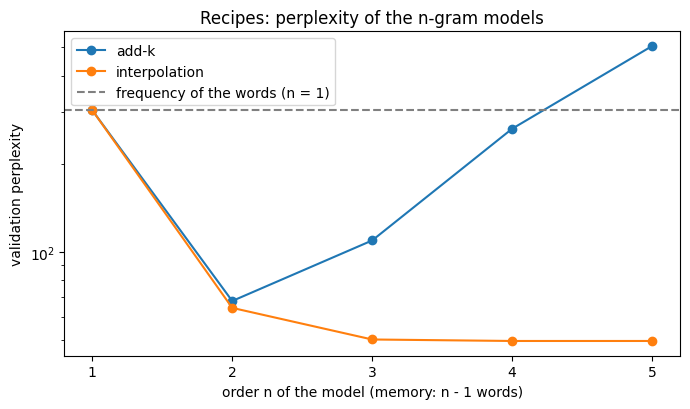

In [11]:
fig, ax = plt.subplots(figsize=(7, 4.2))
table = smoothing["recipes"]
ax.plot(table.index, table["add-k: perplexity"].astype(float), marker="o", label="add-k")
ax.plot(table.index, table["interpolation: perplexity"].astype(float), marker="o", label="interpolation")
ax.axhline(float(table.loc[1, "interpolation: perplexity"]), color="gray", linestyle="--", label="frequency of the words (n = 1)")
ax.set_yscale("log")
ax.set_xticks(range(1, 6))
ax.set_xlabel("order n of the model (memory: n - 1 words)")
ax.set_ylabel("validation perplexity")
ax.set_title("Recipes: perplexity of the n-gram models")
ax.legend()
plt.tight_layout()

### What the models write

Perplexity measures the probability of the words that are really there. To see what the models *know* we let them write, as in the previous notebooks, with the pure counts (the maximum likelihood estimate: at each step the next word is drawn among the ones that followed the context in the training set). We also measure two things on 500 sentences for each order, and we compare them with the real sentences of the validation set, the ones that the model has not seen:

- the share of the **4-grams** (sequences of four consecutive words, with the boundaries of the sentence) of the generated text that occur in the training text: if it is much lower than in the real text, the model is inventing combinations that nobody writes (**incoherence**); if it is higher, it is repeating what it has read (**copying**);
- the share of the generated sentences that are **identical to a sentence of the training set**.

In [12]:
def four_grams(sentences):
    return {t for s in sentences for t in zip(s, s[1:], s[2:], s[3:])}

def generation_study(name, samples=500, seed=0):
    vocabulary, train, validation, test = corpora[name]
    seen_sentences, seen_four_grams = set(train), four_grams(train)
    share_of_four_grams = lambda sentences: np.mean([t in seen_four_grams for s in sentences for t in zip(s, s[1:], s[2:], s[3:])])
    rows = {"real sentences (validation set)": {"4-grams found in the training text": share_of_four_grams(validation),
                                                "sentences identical to a training sentence": np.mean([s in seen_sentences for s in validation]),
                                                "mean length (words)": np.mean([len(s) - 2 for s in validation]),
                                                "reach 30 words": np.mean([len(s) - 2 >= 30 for s in validation])}}
    examples = {}
    for n in range(1, 6):
        rng = np.random.default_rng(seed)
        texts = [model_text for model_text in (models[name][n].generate(rng, method="mle") for _ in range(samples))]
        sentences = [(vocabulary.start,) + tuple(t) + ((vocabulary.end,) if len(t) < 30 else ()) for t in texts]
        rows[f"n = {n}"] = {"4-grams found in the training text": share_of_four_grams(sentences),
                            "sentences identical to a training sentence": np.mean([s in seen_sentences for s in sentences]),
                            "mean length (words)": np.mean([len(t) for t in texts]),
                            "reach 30 words": np.mean([len(t) >= 30 for t in texts])}
        examples[n] = [" ".join(vocabulary.decode(t)) for t in texts[:3]]
    return pd.DataFrame(rows).T, examples

format_generation = {"4-grams found in the training text": "{:.1%}", "sentences identical to a training sentence": "{:.1%}",
                     "mean length (words)": "{:.1f}", "reach 30 words": "{:.1%}"}
generation = {"recipes": generation_study("recipes")}
for n, texts in generation["recipes"][1].items():
    print(f"n = {n}")
    for t in texts:
        print("   ", t)
generation["recipes"][0].style.format(format_generation)

n = 1
    more in
    
    surface bits drain blend cheese because lid <unk> topping
n = 2
    preheat oven
    to rise again with fresh basil seed chop <unk> rum
    toss and scallions to stir in the chicken pieces of your package directs rinse potatoes are crisp and stir together in a little ghee cumin stir until rice is lightly
n = 3
    preheat oven to
    peel starting from long side lift one side about to minutes
    no need to let the mixture as they grill
n = 4
    preheat oven to
    peel starting from the side nearest to you roll up the dough beginning with the edge closest to the stomach entirely empty
    tear several tortillas into smaller pieces about into thirds and sear until just golden to minutes
n = 5
    preheat oven to
    peel starting from the large end towards the point
    toss to coat


,4-grams found in the training text,sentences identical to a training sentence,mean length (words),reach 30 words
real sentences (validation set),41.7%,14.6%,9.9,1.1%
n = 1,0.2%,2.4%,9.0,4.2%
n = 2,14.8%,9.4%,9.4,4.8%
n = 3,59.3%,14.4%,9.8,1.8%
n = 4,100.0%,31.2%,9.3,2.2%
n = 5,100.0%,55.6%,9.9,1.6%


The real sentences of the validation set have 41.7% of their 4-grams in the training text, and 14.6% of them are found whole. These are the points of reference. The text that the models write, with the pure counts, goes from one extreme to the other.

- **$n = 1$**: 0.2% of the 4-grams. It is a list of words of the kitchen (`surface bits drain blend cheese because lid <unk> topping`), with no syntax at all.
- **$n = 2$**: 14.8%, well under the real text. Each pair of words is fine and the sentence is not (`toss and scallions to stir in the chicken pieces of your package directs rinse potatoes ...`): **incoherence**.
- **$n = 3$**: 59.3%, above the real text, and the sentences can be read in pieces (`peel starting from long side lift one side about to minutes`).
- **$n = 4$ and $n = 5$**: 100%, by construction (every word is drawn among those that followed a context of three or four words in the training set, so that every 4-gram that is written has been read). And **31.2% and 55.6% of the sentences are copies of sentences of the training set**, against 14.6% for the real ones (`peel starting from the large end towards the point`). The text is coherent because it is **recited**: the contexts are so rare that after most of them there is only one continuation.

There is no order that writes like the real text: 41.7% would be the right level, and it falls between $n = 2$ (too much invention) and $n = 3$ (too much copying). It is the same trade-off that we saw in the counts, now in the text: with little memory the model lacks coherence, with a lot of memory it lacks data and it copies. The sentences that do not end (the last column) fall with the memory, from 4.2-4.8% ($n = 1, 2$) to 1.6-2.2% ($n = 3, 4, 5$), against 1.1% of the real ones, and the mean length stays at 9-10 words as in the real text.

## Plots of films: the same study

We repeat the three steps on the plots: the counts, the smoothing and the generation. The comparison is not exact, because in the plots 15.8% of the words are replaced by `<unk>` (1.3% in the recipes), and a model with a full vocabulary would have a higher perplexity; but the trends are the ones that matter.

In [13]:
print("Pure counts")
display(maximum_likelihood_table("plots").style.format(format_mle))
smoothing["plots"] = smoothing_table("plots")
print("Smoothing")
display(smoothing["plots"].style.format(format_smoothing))

Pure counts


,training perplexity,validation positions with probability 0,validation perplexity
n,,,
1,278.4,0.0%,257.9
2,60.1,11.6%,inf
3,13.0,42.4%,inf
4,3.8,69.8%,inf
5,2.2,82.5%,inf


Smoothing


,add-k: best k,add-k: perplexity,interpolation: perplexity,"interpolation, weights fitted on the other half","weights of the orders 1, ..., n"
n,,,,,
1,0.0001,257.9,258.0,258.0,1.00
2,0.01,124.1,114.3,114.3,0.24 / 0.76
3,0.01,334.7,106.4,106.4,0.24 / 0.57 / 0.19
4,0.01,1070.6,106.2,106.2,0.24 / 0.57 / 0.18 / 0.01
5,0.01,1909.4,106.2,106.2,0.24 / 0.57 / 0.18 / 0.01 / 0.00


In [14]:
generation["plots"] = generation_study("plots")
for n, texts in generation["plots"][1].items():
    print(f"n = {n}")
    for t in texts[:2]:
        print("   ", t)
generation["plots"][0].style.format(format_generation)

n = 1
    goes to <unk> <unk> five factory father must when step los <unk> kidnapped <unk> use
    coach when and he <unk> <unk> return death over is article hat room next fight is <unk> mr an and she nature devastated of was and time a in system
n = 2
    however the <unk> <unk> opens fire by dr
    fay dance <unk> hears <unk> makes a pressure on the girl <unk> <unk> tells him for a zombie soldier named boss harry is <unk> three year old daughter maggie ward
n = 3
    however the <unk> <unk> breaks through the streets of manhattan and while donna is still a cop arrives <unk> they <unk> the court which finds <unk> address only to find
    eventually the <unk> behind a <unk> for grant casey
n = 4
    however the <unk> <unk> business ken and <unk> go looking for <unk> but <unk> continues and <unk> <unk> to it <unk> <unk> as their lawyer gets them off with just
    eventually the <unk> sends him a line of credit by <unk>
n = 5
    however the <unk> <unk> starts the fire himself and <unk> 

,4-grams found in the training text,sentences identical to a training sentence,mean length (words),reach 30 words
real sentences (validation set),23.4%,2.5%,17.8,10.8%
n = 1,3.1%,1.8%,14.2,19.6%
n = 2,13.9%,3.4%,14.8,18.4%
n = 3,50.4%,4.4%,14.9,18.0%
n = 4,100.0%,6.4%,16.4,17.2%
n = 5,100.0%,28.0%,17.2,13.2%


The plots show the same trends, with more of everything that is bad. With the pure counts the positions with probability zero are 11.6%, 42.4%, 69.8% and 82.5% for $n = 2, \dots, 5$ (7.8%, 28.9%, 48.8% and 60.4% in the recipes), and the perplexity on the training set falls to 2.2. With the interpolation the perplexity goes from 258.0 (no context) to 114.3 with one word of context, 106.4 with two, and 106.2 with three or four: the context helps much less than in the recipes (where the third word brought 22%, here it brings 7%), and the weights say the same thing: the contexts of two or three words have 0.45 of the weight in the recipes ($n = 4$: 0.37 and 0.08) and 0.19 in the plots (0.18 and 0.01). Add-$k$ is worse as before (124.1 for $n = 2$ and then 334.7, 1070.6, 1909.4).

In the generated text the plots are on the same road. The 4-grams of the real validation text that are found in the training set are 23.4%; the model with $n = 3$ gets 50.4% and the ones with $n = 4$ and $n = 5$ 100% (by construction, as before). The sentences copied whole are fewer than in the recipes (6.4% with $n = 4$, 28.0% with $n = 5$, against 2.5% of the real ones), because the sentences of the plots are longer and rarely repeat. Read the samples: they are locally fluent and without a story (`one by one until only tom is left to the <unk> <unk> and <unk> with self confidence laura <unk> a visit from the roman senator marcus <unk> ...`), the people change from one clause to the next, and the names that the model does not know are `<unk>`. One caution: the 4-grams that contain `<unk>` are easy to find in the training text, and 15.8% of the words of the plots are `<unk>`, so that the shares of the 4-grams found are inflated, and we have not measured by how much. The sentences that do not end are still 13-20%, against 10.8% of the real ones.

So the same memory is worth less when the text is more varied, and long sentences with many names need much more text to be counted.

## The test set

We choose the order of the model on the validation set: the one with the lowest perplexity with the interpolation, taking the smaller one when two are equal. For both corpora it is $n = 4$ (the models of order 5 give the same perplexity, since the weight of the fifth order is zero). The weights of the interpolation were fitted on the validation set. The test set, kept aside from the beginning, is used **once**, for these two models and for the frequency of the words.

In [15]:
test_results = {}
for name, (vocabulary, train, validation, test) in corpora.items():
    chosen = models[name][4]
    weights = chosen.fit_weights(validation)
    test_results[name] = {"frequency of the words (n = 1)": models[name][1].perplexity(test, method="mle"),
                          "n-gram model, n = 4, interpolation": chosen.perplexity(test, method="interpolation", weights=weights)}
pd.DataFrame(test_results).T.style.format("{:.1f}")

,frequency of the words (n = 1),"n-gram model, n = 4, interpolation"
recipes,297.3,47.3
plots,259.3,106.9


On the test set the frequency of the words gives 297.3 in the recipes and 259.3 in the plots, and the 4-gram model with interpolation 47.3 and 106.9. They are the values that we had on the validation set (304.6 and 258.0 for the frequency, 49.6 and 106.2 for the model), as they should be for two numbers that were not fitted to the test set. In the previous notebook the table with one word of context gave 65.9 and 123.8 on the same test set. The comparison is not between equals, since here the model looks at three words, but it says that **counting with a good smoothing, with no training at all, is a strong model**: this is the standard that the neural models of the next notebook have to beat.

## One equation, two uses

Under the Markov assumption the probability of a sentence is the product

$$P(w_1, \dots, w_m) = \prod_{t=1}^{m+1} P(w_t \mid w_{t-n+1}, \dots, w_{t-1}),$$

and so far we have used it in one direction: to **write**, by drawing the next word from the distribution and appending it. But the same product can be **evaluated** on a text that is given: it is the probability that the model assigns to that text, and the perplexity that we have been computing is nothing else than this number, averaged over the words.

Evaluating becomes a tool for deciding when we have **more than one model**. Suppose that we train one language model for each class $c$, on the texts of that class only. Each model knows how the texts of its class are written, and gives us $P(\text{text} \mid c)$. With the Bayes rule

$$P(c \mid \text{text}) \propto P(\text{text} \mid c)\, P(c)$$

we can classify a new text by asking **which model finds it most probable**, weighting each class by its frequency $P(c)$. This is a *generative* classifier: in the classification notebooks the network learned $P(c \mid \text{text})$ directly, here we learn how each class writes and derive the decision from it. The set of language models works as an ensemble: each one is a judge that scores the whole text, and the decision compares the scores. With $n = 1$ (the frequency of the words in each class, with add-one smoothing) it is the well-known Naive Bayes classifier, and every higher $n$ is the same classifier with more memory.

We try it on the recipes, with the **instructions** as text (not the ingredients as in the classification notebooks) and the two labels that we already know: the cuisine (10 classes, with 4,271 / 527 / 551 labeled recipes in the training / validation / test sets) and the type of dish (8 classes, 5,664 / 710 / 686). The recipes without a label are not used. The vocabulary and the split by recipe are those of this notebook, and the weights of the interpolation are the same for all the classes (they are fitted on the validation recipes with a model trained on all the classes).

In [16]:
import json
from nlp.ngram import NGramModel

recipe_records = json.load(open(lm.RECIPES))
documents = lm.load_recipes()
train_ids, validation_ids, test_ids = lm.split_documents(list(range(len(documents))))     # the split of the recipes, by document
vocabulary = corpora["recipes"][0]
assert vocabulary.words == lm.Vocabulary([documents[i] for i in train_ids], size=4000).words
V = len(vocabulary)

encoded = {i: [tuple(vocabulary.encode(s)) for s in documents[i]] for i in range(len(documents))}
labeled = {label: [[i for i in part if recipe_records[i][label]] for part in (train_ids, validation_ids, test_ids)]
           for label in ("cuisine", "type")}                      # the recipes that have a label

def class_models(label, n):
    # One language model for each class, trained only on the sentences of the recipes of that class.
    train_i, validation_i, _ = labeled[label]
    classes = sorted({recipe_records[i][label] for i in train_i})
    by_class = {c: [s for i in train_i if recipe_records[i][label] == c for s in encoded[i]] for c in classes}
    models = {c: NGramModel(n, V).fit(by_class[c]) for c in classes}
    # The weights of the interpolation are shared by the classes: fitted on the validation recipes, with a model trained on all of them
    pooled = NGramModel(n, V).fit([s for c in classes for s in by_class[c]])
    weights = pooled.fit_weights([s for i in validation_i for s in encoded[i]])
    prior = np.array([sum(recipe_records[i][label] == c for i in train_i) for c in classes]) / len(train_i)
    return classes, models, weights, np.log(prior)

def log_likelihoods(document_id, classes, models, weights):
    # log P(text | class) for every class: the sum of the log-probabilities of all the words of the recipe
    sentences = encoded[document_id]
    values = []
    for c in classes:
        X, y = models[c].positions(sentences)
        values.append(np.log(models[c].probabilities(X, y, method="interpolation", weights=weights)).sum())
    return np.array(values)

classes, cuisine_models, cuisine_weights, _ = class_models("cuisine", 3)
rng = np.random.default_rng(0)
for c in ["Japanese", "Mexican", "German", "Indian"]:
    print(c)
    for _ in range(3):
        print("  ", " ".join(vocabulary.decode(cuisine_models[c].generate(rng, method="interpolation", weights=cuisine_weights))))

Japanese
   reduce to the <unk> amount like drain on your soba package
   next
   once the fillets in the lemon the heat over low heat to tighten running repeat until one side
Mexican
   time will be corn sugars burnt onto a boil for minutes
   gradually add cheese
   arrange like a burrito
German
   oven and let rise in the egg until to hours
   spoon to steaks with the size rinse is mostly browned about inch link chopped green beans and let rise until doubled about teaspoons of dried lavender flowers
   strain measuring apple
Indian
   seafood ghee aside heat the turmeric paprika red chili powder turmeric
   garnish with
   transfer the fried green cardamom and bay water and simmer partially covered until chicken thin the water and make put bread mixture into a min or rotis or bread or


First the direction we know. Here are three sentences from each of four cuisines, with $n = 3$: the only difference among the four models is the text they have been trained on (about 430 recipes each).

Some words reveal the class (`soba` for the Japanese model, `burrito` for the Mexican one, `ghee`, `turmeric`, `cardamom` and `rotis` for the Indian one), and the sentences are as locally plausible and as meaningless as the ones of the previous sections. This is a reading of a few samples, not a measure.

The other direction is the new one. For a recipe we compute, with each class model, the sum of the logarithms of the probabilities of all its words, which is $\log P(\text{text} \mid c)$, we add $\log P(c)$ and we compare. Here is the first labeled recipe of the validation set (we have not chosen it) with the four best classes.

In [17]:
classes, models, weights, log_prior = class_models("cuisine", 3)
i = labeled["cuisine"][1][0]                  # the first labeled recipe of the validation set (not chosen)
print(recipe_records[i]["title"], "| true cuisine:", recipe_records[i]["cuisine"])
print(" ".join(" ".join(s) for s in documents[i])[:300], "...")
scores = pd.DataFrame({"log P(text | class)": log_likelihoods(i, classes, models, weights), "log P(class)": log_prior}, index=classes)
scores["sum"] = scores.sum(axis=1)
scores.sort_values("sum", ascending=False).head(4).style.format("{:.1f}")

Indian Wedding Soup | true cuisine: Indian
melt butter in large dutch oven and cook onions and garlic until soft over medium low heat add carrots potatoes and stock bring to a boil and reduce heat to a simmer cook until potatoes are soft add chard and pasta and cook a further minutes until pasta is cooked add meatballs and heat through serve ...


,log P(text | class),log P(class),sum
Mexican,-205.9,-2.2,-208.0
Greek,-211.8,-2.3,-214.1
Indian,-214.6,-2.3,-216.8
Moroccan,-215.1,-2.3,-217.4


The values of $\log P(\text{text} \mid c)$ are all around $-210$: the probability of a whole recipe is tiny for every model, and **only the differences matter**. The prior is the same for all the classes, almost ($\log 0.1 = -2.3$), and is irrelevant here. The model prefers Mexican to Indian by 8.8 units, which is a factor of several thousands in probability, but it is a small difference compared with the size of the numbers.

The example is not a success. The recipe is called "Indian Wedding Soup" and its label is `Indian`, but the instructions describe a generic soup (butter, onions, carrots, potatoes, pasta, meatballs) and nothing in the text is Indian: the label comes from where the recipe was published, the model only sees the words. It is a reminder that a classifier of this kind can only be as good as the **text** is informative about the class. We now measure how often it is right on the validation set, for the memory $n = 1, \dots, 4$.

In [18]:
def classification_study(label, n, part):
    classes, models, weights, log_prior = class_models(label, n)
    ids = labeled[label][part]
    predicted = [classes[int(np.argmax(log_likelihoods(i, classes, models, weights) + log_prior))] for i in ids]
    return np.mean([p == recipe_records[i][label] for p, i in zip(predicted, ids)])

baseline = {label: max(Counter(recipe_records[i][label] for i in labeled[label][0]).values()) / len(labeled[label][0])
            for label in ("cuisine", "type")}
accuracy = pd.DataFrame({label: {n: classification_study(label, n, 1) for n in range(1, 5)} for label in ("cuisine", "type")})
accuracy.index.name = "n"
accuracy.loc["most frequent class"] = baseline
accuracy.style.format("{:.1%}")

,cuisine,type
n,,
1,60.3%,67.0%
2,56.2%,66.2%
3,57.9%,65.1%
4,57.1%,64.9%
most frequent class,11.6%,15.3%


The majority class would be right in 11.6% of the recipes for the cuisine and 15.3% for the type, and the class models are right in 60.3% and 67.0% of the cases with $n = 1$. So the instructions carry a lot of information about the class, even if the model does not know that `soy sauce` is a Japanese ingredient: it only counts words.

The result that matters for this notebook is that **more memory does not help**. With $n = 2, 3, 4$ the accuracy is 56.2, 57.9 and 57.1% for the cuisine and 66.2, 65.1 and 64.9% for the type, never better than with the frequencies of the words alone. The differences among the higher orders are small and not tested: with 527 and 710 recipes the uncertainty of each number is about two points. The trade-off of the previous sections is at work again. Each class model sees only a tenth (or an eighth) of the corpus, so the contexts of two or three words are even rarer than in the whole corpus, and the interpolation, whose weights we did not fit for each class, cannot make up for it. This is a plausible reading that we have not tested. It also suggests that the words alone are enough for these labels, since the instructions name the foods and the tools that distinguish the classes.

In [19]:
for label in ("cuisine", "type"):
    print(f"{label}: n = 1, test accuracy {classification_study(label, 1, 2):.1%}")

cuisine: n = 1, test accuracy 54.1%


type: n = 1, test accuracy 67.3%


We choose $n = 1$ for both labels on the validation set and look at the test set once. The type of dish gives 67.3% (686 recipes), as on the validation set. The cuisine gives 54.1% (551 recipes), six points less than the 60.3% of the validation set. With about 500 recipes one accuracy has an uncertainty of two points, so a gap of six is larger than the noise we would expect, and we have not investigated it. Both numbers are far from the 11.6% and 15.3% of the majority class.

We do not compare these values with the ones of the classification notebooks, which used other inputs (the ingredients) and another split. What we want to keep is the idea: **the equation of the language model works in two directions**. Used to *generate*, it draws a word after the other. Used to *evaluate*, it gives the probability of a text, and with one model for each class this probability becomes a decision. Every language model that gives $P(w \mid \text{history})$ can be used in both ways, including the neural ones of the next notebook.

## What the counts cannot do

The interpolated models are a decent answer to the problem of the events that we have never seen, and they are the best that counting can do. But they leave a problem that no smoothing can fix, and that we can see in the recipes. The model estimates each context **on its own**: it knows what follows `lime`, and it knows what follows `lemon`, but what it learns about one does not help with the other, even though the two words are used in nearly the same way. It borrows information from the shorter contexts, and never from the **similar** ones.

Here is an example (the pairs of words are chosen by us, because we know that they behave in the same way). In the validation set we look for the sequences of three words that contain one of them and have never been seen in the training set, whose version with the other word **has** been seen.

In [20]:
vocabulary, train, validation, test = corpora["recipes"]
trigrams = Counter(t for s in train for t in zip(s, s[1:], s[2:]))
unseen_trigrams = sum(1 for s in validation for t in zip(s, s[1:], s[2:]) if trigrams[t] == 0)
print(f"Sequences of three words of the validation set that have never been seen in the training set: {unseen_trigrams:,}")

rows = {}
for word, similar in [("lime", "lemon"), ("lemon", "lime"), ("saucepan", "skillet"), ("skillet", "saucepan"), ("thyme", "oregano"), ("oregano", "thyme")]:
    a, b = vocabulary.index[word], vocabulary.index[similar]
    found = [(t, trigrams[tuple(b if x == a else x for x in t)]) for s in validation for t in zip(s, s[1:], s[2:])
             if a in t and trigrams[t] == 0 and trigrams[tuple(b if x == a else x for x in t)] > 0]
    rows[f"{word} (instead of {similar})"] = {"unseen sequences that the other word has seen": len(found),
                                              "examples (times seen with the other word)": ";  ".join(f"{' '.join(vocabulary.decode(t))} ({c})" for t, c in list(dict(found).items())[:3])}
pd.DataFrame(rows).T.style.format(escape="html").set_properties(**{"text-align": "left"}).set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])

Sequences of three words of the validation set that have never been seen in the training set: 33,262


,unseen sequences that the other word has seen,examples (times seen with the other word)
lime (instead of lemon),23,lime juice as (2); garnished with lime (1); lime <unk> </s> (3)
lemon (instead of lime),11,lemon juice fish (5); of lemon to (2); the yogurt lemon (1)
saucepan (instead of skillet),13,saucepan and continue (1); water in saucepan (1); saucepan to cook (1)
skillet (instead of saucepan),7,medium skillet or (1); skillet stirring for (1); over skillet to (1)
thyme (instead of oregano),9,and thyme together (1); thyme and red (1); and thyme to (2)
oregano (instead of thyme),13,the oregano in (1); the fresh oregano (2); fresh oregano </s> (2)


In the validation set 33,262 sequences of three words have never been seen in the training set, and each one gets from the interpolation only what the shorter contexts can say. The table shows a small sample of the cases in which the information was there, with a **similar word**: `lime juice as` has not been seen and `lemon juice as` has (twice), and the same happens with `garnished with lime`, with `saucepan and continue` (`skillet and continue` has been seen) and with `the fresh oregano` (seen twice with `thyme`). There are only 76 of them in all, because we have chosen only three pairs of words (in both directions), and they are not a measure of what is lost: they show the mechanism. The interpolation borrows from the contexts that are *shorter*, never from the ones that are *similar*: the counts of `lemon` are no help for `lime`.

This is the limit that no smoothing can remove. Two words that are used in the same way, as the vectors of the previous notebooks show (`lemon` and `lime` are close), are for a count-based model two unrelated symbols, and every new context has to be seen again from scratch. To generalize we need a model that **computes** the probability of the next word from a representation of the context in which similar words are close, and whose parameters are shared among all the contexts. This is what the network of Word2Vec does with words, and it is the subject of the next notebook.

## What we have learned

- **The ideal language model uses the whole history**, and the chain rule decomposes it exactly. But it cannot be estimated by counting: only 14.6% of the validation sentences of the recipes (2.5% of the plots) have been seen whole, and with five words of history 77.5% of the positions of the training set have a history that occurs only once (96.1% in the plots). The index would be as large as the corpus.
- **The Markov assumption** limits the history to the last $n - 1$ words and makes the counts possible, at the price of a trade-off. In the toy example two words of memory remove the impossible sentences (from 6.4% to none); in the recipes, with $n = 3$ the pairs (context, next word) of the validation set that have been seen are 71.1% and with $n = 5$ 39.6%.
- **Counts without any restraint overfit**: with the pure counts the perplexity on the training set falls to 3.3, and on the validation set it is infinite, because 7.8% to 60.4% of the positions have probability zero.
- **Interpolation of the orders is an approximation of the probability of what we have not seen** that works: 49.6 on the validation set of the recipes with $n = 4$ (47.3 on the test set), 106.2 on the plots (106.9), against 304.6 and 258.0 of the frequency of the words. Add-$k$ smoothing is not enough once the memory grows.
- **The trade-off is visible in the text.** With $n = 2$ the sentences are incoherent (14.8% of the 4-grams occur in the training set, against 41.7% in the real text); with $n = 4$ and $n = 5$ they are recited (31.2% and 55.6% of the sentences are copies). In the plots, with longer and more varied sentences, the long contexts are worth less.
- **The same equation works in two directions.** It writes a text by drawing word after word, and it evaluates a text by multiplying the probabilities. With one model per class and the Bayes rule the evaluation becomes a classifier: on the recipes it is right in 54.1% of the cuisines and 67.3% of the types (test set, $n = 1$, which is Naive Bayes), and more memory does not help because each class has little text.
- **What counting cannot do.** It gives the same weight to what is seen and what is similar to what is seen: `lime` does not learn from `lemon`. The probability of the next word has to be **approximated by a function** whose parameters are shared among the contexts, so that what is learned in one place is used in another.

The next notebook builds that function with the network of Word2Vec: the embeddings of the words of the context, combined in different ways, predict the next word. We will compare it with the models of this notebook at the same memory, and we will see what it improves (the generalization between similar words) and what remains a problem (the memory is still a fixed window of words, and the text that it writes still has no plan).

For the discussion: *(a)* why does the weight of the fifth order go to zero in the interpolation, and what would you expect if the corpus were ten times larger? *(b)* the 4-grams of the text generated with $n = 4$ are all in the training set: why is it so, and why is it not true for $n = 3$? *(c)* with a vocabulary of 20,000 words instead of 4,000, which of the tables of this notebook would change the most?